# wellfit: grid-search example (line broadening)

Let's suppose we want to fit v sin i and v_macro to four absorption lines (A-D) with a grid of broadened models, and quote honest
errors.

The spectrum is synthetic (`toy_lines.py`):

- The line centres, equivalent widths and intrinsic widths are known. Only the broadening is fitted, so
  `n_params = 2`.
- True values: v sin i = 100 km/s, v_macro = 10 km/s.
- The noise is correlated over a few pixels, which could happen when rebinning or stacking.
- The observed errors are too small.
- Line D has v sin i = 140 km/s. An example of a line with a problem (blend, poor model, normalization error).

The naive recipe assumes the observed errors and n_pix − n_params degrees of freedom are correct, and treats all lines as equally
trustworthy. Below we compare it with wellfit.

In [1]:
import sys
sys.path.insert(0, '..')   # or install the package: pip install -e ..
import numpy as np
import matplotlib.pyplot as plt
import wellfit as wf
import toy_lines as tl     # toy broadening model + synthetic data for these examples
%matplotlib inline

## 1. Data

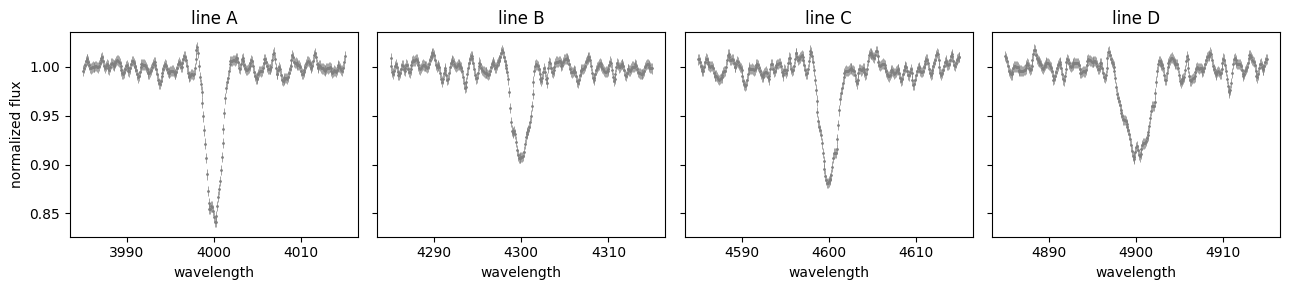

In [2]:
# Select a set of "true" parameters for the synthetic data
TRUTH = dict(vsini=100., vmacro=10., vsini_D=140., snr=150.)

# Generate synthetic data with the above parameters
d = tl.make_data(**TRUTH)
lam_obs, flux_obs, err_obs, groups, names = d['lam'], d['flux'], d['err'], d['groups'], d['names']

# Plot the synthetic data
fig, axs = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for j, ax in enumerate(axs):
    m = groups == j
    ax.errorbar(lam_obs[m], flux_obs[m], err_obs[m], fmt='.', ms=2, color='0.5', lw=0.5)
    ax.set_title(f'line {names[j]}'); ax.set_xlabel('wavelength')
axs[0].set_ylabel('normalized flux'); plt.tight_layout()

## 2. Noise: rescale the errors and measure the pixel correlation

Both come from the line-free continuum on either side of each line (`d['ref_ranges']`). A constant baseline (`deg=0`) is
fitted in each range because the data are already normalized.

- `measure_error_scale` multiplies the quoted errors so the continuum scatter has unit width. The data were made with
  errors quoted 0.8x too small, so expect a factor of about 1.25.
- `measure_n_corr` measures how many neighbouring pixels share one independent piece of information. The noise was
  smoothed over about 1.5 pixels, so expect n_corr ≈ 5. Short continuum segments bias the estimate slightly low.

error scale factor = 1.26   (injected 1 / 0.8 = 1.25)


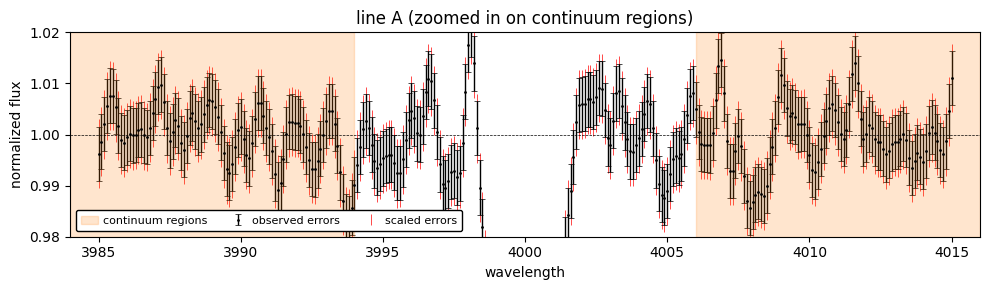

In [3]:
# Measure the error scale factor (i.e., how much the observed errors need to be scaled to match the actual scatter)
err, factor = wf.measure_error_scale(lam_obs, flux_obs, err_obs, d['ref_ranges'], deg=0)
print(f"error scale factor = {factor:.2f}   (injected 1 / 0.8 = 1.25)")

# Plot the measured error scale factor for one of the lines, zoomed in on continuum regions
fig, ax = plt.subplots(1, 1, figsize=(10, 3))
m = groups == 0
ax.errorbar(lam_obs[m], flux_obs[m], err_obs[m], fmt='.', ms=2, color='k', lw=1, zorder=1, capthick=0.5, capsize=2, label='observed errors')
# Scale the errors by the measured factor to show that the scatter is now consistent with the errors
ax.errorbar(lam_obs[m], flux_obs[m], err_obs[m] * factor, fmt='None', ms=2, color='red', lw=0.5, zorder=0, label='scaled errors')
ax.set_title(f'line {names[0]} (zoomed in on continuum regions)'); ax.set_xlabel('wavelength'); ax.set_ylabel('normalized flux')
for j in range(2):
    ax.axvspan(d['ref_ranges'][j][0], d['ref_ranges'][j][1], color='C1', alpha=0.2, label='continuum regions' if j == 0 else None)
ax.set_xlim(d['ref_ranges'][0][0], d['ref_ranges'][1][1]); plt.tight_layout()
ax.axhline(1, color='k', ls='--', lw=0.5)
ax.set_ylim(0.98, 1.02)
ax.legend(loc='lower left', fontsize=8, frameon=True, 
          framealpha=1, fancybox=True, edgecolor='k', facecolor='w', handlelength=1.5, handletextpad=0.5, borderpad=0.5, ncol=3)
plt.tight_layout()

In [4]:
# Measure the number of correlated pixels and the correlation coefficients
n_corr, rho = wf.measure_n_corr(lam_obs, flux_obs, err_obs, d['ref_ranges'], deg=0)
print(f"n_corr = {n_corr:.2f}   (injected {d['truth']['n_corr']:.2f}); rho_1..4 = {np.round(rho[:4], 2)}")
print(f"{lam_obs.size} pixels -> {lam_obs.size / n_corr:.0f} independent pixels")

n_corr = 4.94   (injected 5.32); rho_1..4 = [0.88 0.62 0.34 0.13]
1204 pixels -> 244 independent pixels


## 3. The grid and its residual matrix

The grid stream needs only the residuals model − data of every grid model on the fitted pixels, shape
(n_models, n_pix), plus which line each pixel belongs to (`groups`). How the models are made does not matter.

In [5]:
vsini_axis, vmacro_axis = np.arange(0, 201, 2.), np.arange(0, 61, 2.)
VS, VM = [a.ravel() for a in np.meshgrid(vsini_axis, vmacro_axis, indexing='ij')]   # flattened grid
R = np.stack([tl.model(lam_obs, groups, vs, vm) for vs, vm in zip(VS, VM)]) - flux_obs
print(R.shape, '(n_models, n_pix)')

(3131, 1204) (n_models, n_pix)


## 4. Naive fit vs wellfit

- **Naive:** quoted errors, every pixel independent (`n_corr=1`), no systematic floor.
- **wellfit:**
  - rescaled errors;
  - chi2 and degrees of freedom counted in independent pixels (`chi2_eff = chi2 / n_corr`);
  - a floor `sigma_sys` so the best model has reduced chi2_eff = 1;
  - per-line diagnostics, and systematic errors from a bootstrap over lines.

In [6]:
params = {'vsini': VS, 'vmacro': VM}
naive = wf.fit_grid(R, err_obs, n_corr=1., n_params=2, params=params, fit_sigma_sys=False)
fit = wf.fit_grid(R, err_obs, n_corr, n_params=2, groups=groups, params=params, group_names=names)

print(f"naive: chi2 = {naive.chi2[naive.best]:.0f} for n_pix - n_params = {naive.nu:.0f} dof "
      f"(reduced chi2 = {naive.chi2[naive.best] / naive.nu:.1f})")
for k in params:
    v, ep, em, _, _ = naive.results[k]
    print(f"  {k:7s} = {v:5.0f} +{ep:.0f} -{em:.0f}")
print()
print(fit.summary())

naive: chi2 = 2887 for n_pix - n_params = 1202 dof (reduced chi2 = 2.4)
  vsini   =   106 +2 -2
  vmacro  =    22 +2 -2

n_data = 1204, n_corr = 4.94 -> 243.8 independent points, nu = 241.8
sigma_sys = 0.00635; best model 1654: chi2 = 2886.7 (raw), chi2_eff = 241.8
Parameters (value +stat -stat, +sys -sys):
  vsini             106  +4 -4   sys +10 -6
  vmacro             22  +6 -4   sys +6 -10
Groups (chi2_eff / expected, tension, leave-one-out best vsini, vmacro):
  A                0            40.9 /   60.9  tension    6.1  110  28
  B                0            43.3 /   60.9  tension    0.7  106  26
  C                0            56.7 /   60.9  tension    3.0  110  24
  D                0           100.9 /   60.9  tension   18.1  100  14


The naive fit has a reduced chi2 well above 1 but still quotes errors of about one grid step. wellfit counts about
5× fewer independent pixels and adds the systematic floor that the misfit calls for. Its stat errors are wider, and
the bootstrap over lines adds a systematic error.

The line table shows the problem: **line D has a large tension**. Leaving it out lowers the chi2_eff of the other
three lines by that much, and its leave-one-out best v sin i, the fit without D, differs from the rest.

## 5. Confidence regions

Δchi2 = 2.30 contains 68% for two parameters jointly. Both fits still include line D, which pulls them away from the
truth. The naive region is so small it excludes the truth by far. The wellfit region is honest about the errors, but
it can't remove the bias of a bad line. That is the job of the tension in the next section.

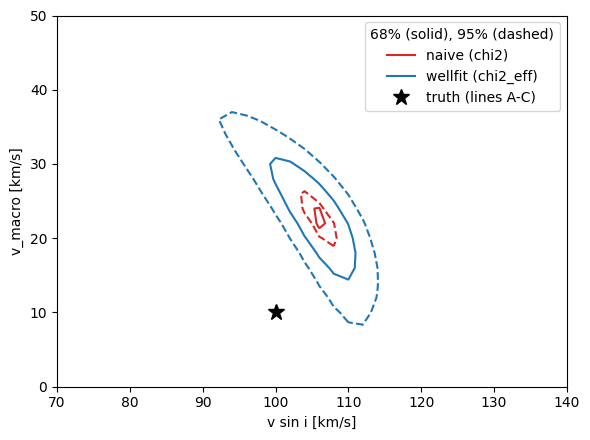

In [7]:
def dchi2_map(c2):
    c2 = c2.reshape(vsini_axis.size, vmacro_axis.size)
    return (c2 - c2.min()).T

fig, ax = plt.subplots(figsize=(6, 4.5))
for c2, col, lab in [(naive.chi2, 'C3', 'naive (chi2)'), (fit.chi2_eff, 'C0', 'wellfit (chi2_eff)')]:
    ax.contour(vsini_axis, vmacro_axis, dchi2_map(c2), levels=[2.30, 6.18], colors=col, linestyles=['-', '--'])
    ax.plot([], [], color=col, label=lab)
ax.plot(TRUTH['vsini'], TRUTH['vmacro'], 'k*', ms=12, label='truth (lines A-C)')
ax.set_xlim(70, 140); ax.set_ylim(0, 50)
ax.set_xlabel('v sin i [km/s]'); ax.set_ylabel('v_macro [km/s]'); ax.legend(title='68% (solid), 95% (dashed)')
plt.tight_layout()

## 6. Line diagnostics: tension

Each line's tension is how much the other lines' chi2_eff drops when that line is left out and the grid refitted.
Consistent lines sit near 0 (a few units by chance). Here line D stands out, so we drop it and refit.

n_data = 903, n_corr = 4.94 -> 182.8 independent points, nu = 180.8
sigma_sys = 0.001247; best model 1557: chi2 = 923.9 (raw), chi2_eff = 180.8
Parameters (value +stat -stat, +sys -sys):
  vsini             100  +4 -2   sys +4 -2
  vmacro             14  +2 -8   sys +2 -8
Groups (chi2_eff / expected, tension, leave-one-out best vsini, vmacro):
  A                0            47.9 /   60.9  tension    0.7  102  8
  B                0            61.4 /   60.9  tension    0.3  98  16
  C                0            71.5 /   60.9  tension    0.7  102  12


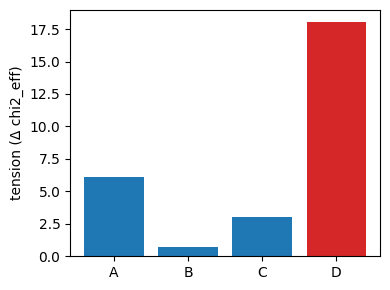

In [8]:
fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(names, fit.tension, color=['C0'] * 3 + ['C3'])
ax.set_ylabel('tension (Δ chi2_eff)'); plt.tight_layout()

keep = groups != names.index('D')
fit_noD = wf.fit_grid(R[:, keep], err[keep], n_corr, n_params=2, groups=groups[keep], params=params,
                      group_names=names[:3])
print(fit_noD.summary())

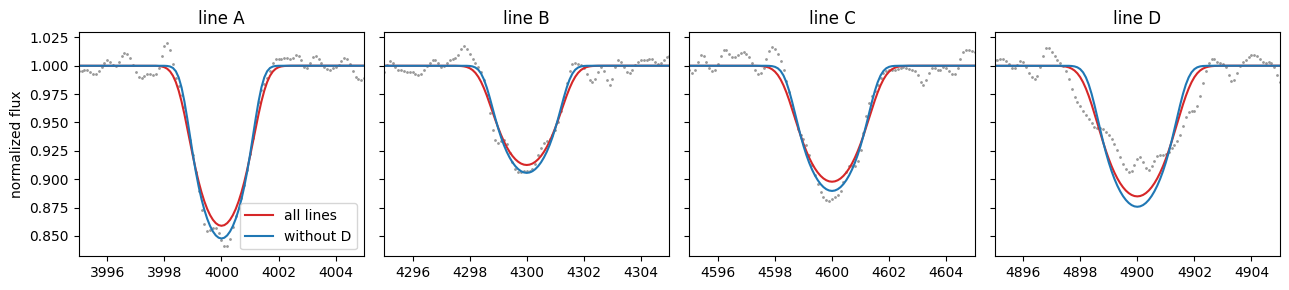

In [9]:
best = lambda f: tl.model(lam_obs, groups, VS[f.best], VM[f.best])
fig, axs = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for j, ax in enumerate(axs):
    m = groups == j
    ax.plot(lam_obs[m], flux_obs[m], '.', ms=2, color='0.6')
    ax.plot(lam_obs[m], best(fit)[m], 'C3', label='all lines')
    ax.plot(lam_obs[m], best(fit_noD)[m], 'C0', label='without D')
    ax.set_title(f'line {names[j]}'); ax.set_xlim(tl.LINES[names[j]][0] - 5, tl.LINES[names[j]][0] + 5)
axs[0].legend(); axs[0].set_ylabel('normalized flux'); plt.tight_layout()

## 7. The 2D posterior: lines A-D vs lines A-C

The two panels below compare the fit with all four lines and the fit without line D. Each shows:

- the posterior exp(−chi2_eff/2), shaded, with its 68% and 95% contours for two parameters (Δchi2_eff = 2.30, 6.18);
- the best fit in each bootstrap replicate over lines (points);
- the best fit and the truth.

**With line D:**

- The posterior sits away from the truth.
- The bootstrap points scatter far outside the contours. Replicates that leave out D land near the truth, and those
  that count it twice land far off. The lines disagree with each other more than the noise allows, so the sys error
  exceeds the stat error.
- The misfit also forces a larger `sigma_sys`, which broadens the contours.

**Without line D:**

- The lines agree, so `sigma_sys` drops by about 4× and the contours shrink.
- The bootstrap points collapse into the contours, so sys ≈ stat.
- The posterior contains the truth.

The tension diagnostic is what tells you which line to examine. Removing a line should be justified by a reason
(a blend, a poor model), not by the tension alone.

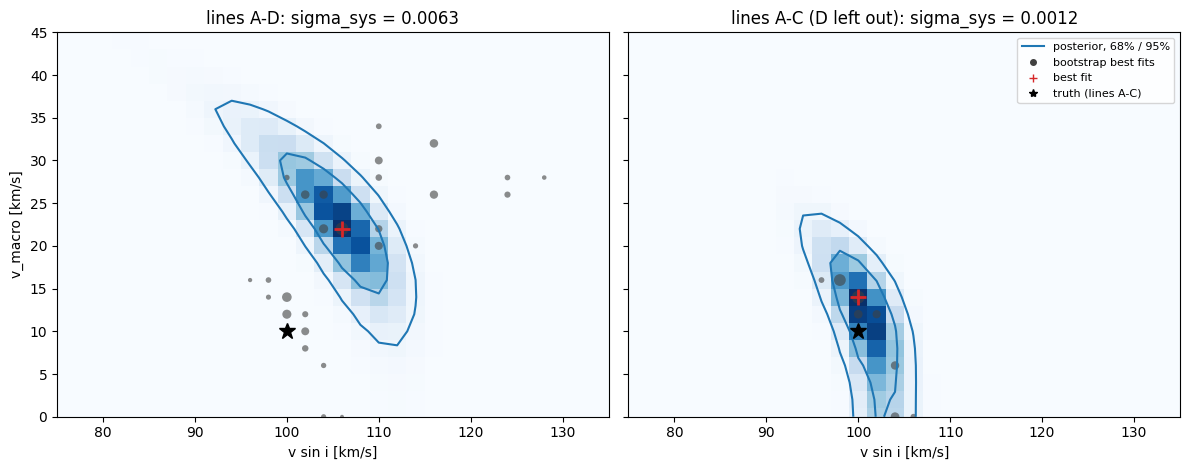

In [10]:
def plot_post2d(ax, d2, x, y, best, boot=None, d2_curv=None, title=''):
    # posterior exp(-Delta chi2_eff / 2) on the (y, x) mesh, its 68% / 95% contours (2 parameters), the curvature
    # ellipses, and the bootstrap best fits (marker size = number of replicates at that point)
    ax.pcolormesh(x, y, np.exp(-0.5 * d2), cmap='Blues', shading='auto')
    ax.contour(x, y, d2, levels=[2.30, 6.18], colors='C0', linestyles='-')
    if d2_curv is not None:
        ax.contour(x, y, d2_curv, levels=[2.30, 6.18], colors='C1', linestyles='--')
    if boot is not None:
        pts, n = np.unique(np.round(boot, 4), axis=0, return_counts=True)
        ax.scatter(*pts.T, s=6 + 80 * n / n.max(), color='0.25', alpha=0.6, lw=0)
    ax.plot(*best, 'C3+', ms=12, mew=2)
    ax.plot(TRUTH['vsini'], TRUTH['vmacro'], 'k*', ms=12)
    ax.set_xlim(x[0], x[-1]); ax.set_ylim(y[0], y[-1])
    ax.set_title(title); ax.set_xlabel('v sin i [km/s]')

def legend2d(ax, ellipse=False):
    items = [('posterior, 68% / 95%', dict(color='C0'))]
    items += [('curvature ellipse', dict(color='C1', ls='--'))] if ellipse else []
    items += [('bootstrap best fits', dict(color='0.25', marker='o', ms=4, ls='')),
              ('best fit', dict(color='C3', marker='+', ls='')), ('truth (lines A-C)', dict(color='k', marker='*', ls=''))]
    for lab, kw in items:
        ax.plot([], [], label=lab, **kw)
    ax.legend(fontsize=8, loc='upper right')

fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, f, t in [(axs[0], fit, 'lines A-D'), (axs[1], fit_noD, 'lines A-C (D left out)')]:
    plot_post2d(ax, dchi2_map(f.chi2_eff), vsini_axis, vmacro_axis, (VS[f.best], VM[f.best]),
                boot=np.stack([VS[f.boot_best], VM[f.boot_best]], axis=1),
                title=f"{t}: sigma_sys = {f.sigma_sys:.4f}")
for ax in axs:
    ax.set_xlim(75, 135); ax.set_ylim(0, 45)
axs[0].set_ylabel('v_macro [km/s]'); legend2d(axs[1]); plt.tight_layout()

## Summary

| | how |
|---|---|
| errors | `measure_error_scale` on line-free ranges |
| correlated pixels | `measure_n_corr`, then chi2_eff = chi2 / n_corr and ν = n_pix / n_corr − n_params |
| imperfect models | `sigma_sys` such that reduced chi2_eff = 1 |
| which data disagree | per-group `tension` and leave-one-out fits |
| errors | stat from the posterior exp(−chi2_eff/2), at least one grid step; sys from the bootstrap over groups |

See `optimizer_example.ipynb` for the same analysis with a continuous minimizer.